In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
z_min, z_max = 0, 100 #m
N = 10 
z_data = np.linspace(z_min + 1, z_max, N)
M_true = 5
h_true = (z_max - z_min) / M_true
velocity = np.full(M_true, 3000)
boundary = M_true // 2
velocity[boundary:] += 1000
slowness = 1 / velocity

20.0


In [53]:
def travel_times(z_data, h, slowness):
    N = z_data.size
    times = np.zeros(N)
    for i in range(N):
        full_layers = (z_data // h)
        distance_in_a_layer = z_data % h
        j = 0
        for j in range(int(full_layers[i])):
            times[i] += slowness[j] * h
        times[i] += distance_in_a_layer[i] * slowness[j]

    return times

data = travel_times(z_data, h_true, slowness)
data

array([0.00033333, 0.004     , 0.00766667, 0.01133333, 0.015     ,
       0.01866667, 0.02008333, 0.02283333, 0.02558333, 0.02833333])

10 30


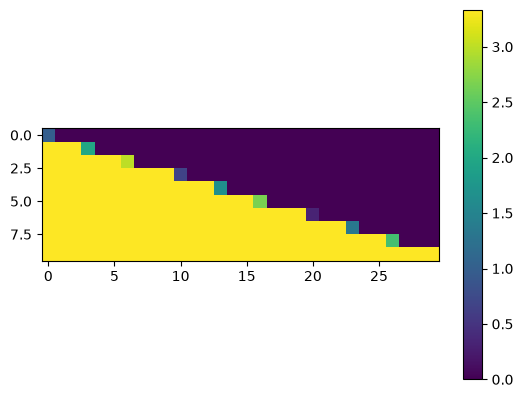

In [91]:
N = z_data.size
M = 30
h = (z_max - z_min) / M
G = np.zeros((N, M))
times = np.zeros(N)
for i in range(N):
    full_layers = (z_data // h)
    distance_in_a_layer = z_data % h
    j = -1
    for j in range(int(full_layers[i])):
        G[i,j] = h
    if j + 1 < M:
        G[i,j + 1] = distance_in_a_layer[i]

print(N,M)
plt.imshow(G)
plt.colorbar()

In [88]:
p = np.linalg.solve(G.T @ G, G.T @ data)
print(p)

LinAlgError: Singular matrix

In [104]:
U, S, Vt = np.linalg.svd(G)

Vt.T.shape, S.shape

((30, 30), (10,))

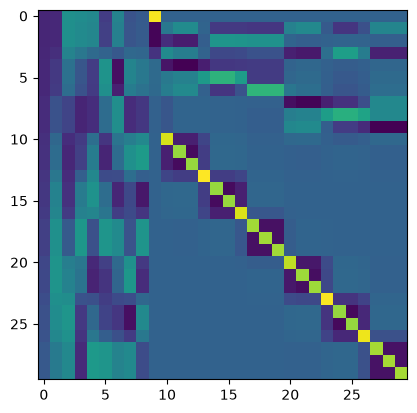

In [108]:
plt.imshow(Vt.T) # Espaço nulo do modelo